# Inferență Bayesiană și simulare Monte Carlo

**Obiectiv.** Aplicăm actualizarea Bayesiană pentru un parametru necunoscut (Exercițiul 1) și folosim simulări Monte Carlo pentru a evalua performanța unui sistem de servire (Exercițiul 2).

Notebook-ul este reproductibil: toate simulările folosesc o sămânță fixă. Rulați celulele în ordine (*Runtime → Run all* în Google Colab).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import betaln, comb

plt.rcParams["figure.figsize"] = (9, 4.8)
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

---
# Exercițiul 1. Controlul calității într-o fabrică (inferență Bayesiană)

Fie $\theta$ probabilitatea ca o componentă aleasă aleatoriu să fie defectă.
Distribuția a priori: $\theta \sim \mathrm{Beta}(a_0, b_0) = \mathrm{Beta}(2, 18)$.
Date: din $n = 50$ componente testate, $y = 8$ sunt defecte.

In [2]:
a0, b0 = 2, 18      # parametrii distributiei a priori
n, y = 50, 8        # datele observate

## a) Modelul probabilistic

Fiecare componentă testată este o variabilă Bernoulli: $Z_i \mid \theta \sim \mathrm{Bernoulli}(\theta)$, $i = 1,\dots,50$, independente condiționat de $\theta$.
Numărul de defecte $Y = \sum_{i=1}^{50} Z_i$ are deci distribuția binomială:

$$
Y \mid \theta \sim \mathrm{Bin}(n = 50,\ \theta).
$$

**Funcția de verosimilitate** (ca funcție de $\theta$, pentru $y$ fixat):

$$
L(\theta) = P(Y = y \mid \theta) = \binom{n}{y}\,\theta^{y}(1-\theta)^{n-y}
= \binom{50}{8}\,\theta^{8}(1-\theta)^{42}, \qquad \theta \in [0,1].
$$

In [3]:
def verosimilitate(theta):
    return comb(n, y) * theta**y * (1 - theta)**(n - y)

print(f"Coeficientul binomial C(50, 8) = {comb(n, y, exact=True):,}")
print(f"L(0.10) = {verosimilitate(0.10):.5f}")
print(f"L(0.16) = {verosimilitate(0.16):.5f}   (maximul, vezi punctul c)")

Coeficientul binomial C(50, 8) = 536,878,650
L(0.10) = 0.06428
L(0.16) = 0.15225   (maximul, vezi punctul c)


## b) Actualizarea Bayesiană

Densitatea a priori Beta este

$$
p(\theta) = \frac{\theta^{a_0-1}(1-\theta)^{b_0-1}}{B(a_0,b_0)}, \qquad B(a,b)=\int_0^1 t^{a-1}(1-t)^{b-1}\,dt .
$$

Din formula lui Bayes:

$$
p(\theta \mid y) = \frac{P(y\mid\theta)\,p(\theta)}{\int_0^1 P(y\mid t)\,p(t)\,dt} \;\propto\; P(y\mid\theta)\,p(\theta).
$$

Înlocuind:

$$
p(\theta\mid y) \propto \theta^{y}(1-\theta)^{n-y}\cdot \theta^{a_0-1}(1-\theta)^{b_0-1}
= \theta^{(a_0+y)-1}(1-\theta)^{(b_0+n-y)-1}.
$$

Aceasta este, până la o constantă, densitatea unei distribuții Beta. Constanta de normalizare este unic determinată (densitatea trebuie să integreze la 1), deci

$$
\boxed{\theta \mid Y=y \;\sim\; \mathrm{Beta}(a_0 + y,\; b_0 + n - y) = \mathrm{Beta}(2+8,\; 18+42) = \mathrm{Beta}(10,\, 60).}
$$

**Conjugarea Beta–Binomial:** distribuția a priori și cea a posteriori aparțin aceleiași familii (Beta). Datele doar actualizează parametrii: $a$ crește cu numărul de defecte, iar $b$ cu numărul de componente bune. Putem interpreta $a_0=2$, $b_0=18$ ca pe „20 de observații fictive anterioare, dintre care 2 defecte”.

Verificăm numeric că normalizarea directă a produsului verosimilitate × a priori dă exact Beta(10, 60):

In [4]:
a_post, b_post = a0 + y, b0 + n - y
prior = stats.beta(a0, b0)
post = stats.beta(a_post, b_post)
print(f"A posteriori: Beta({a_post}, {b_post})")

# verificare numerica: normalizam produsul verosimilitate x a priori pe o grila
grila = np.linspace(0, 1, 200_001)
nenorm = verosimilitate(grila) * prior.pdf(grila)
post_numeric = nenorm / np.trapezoid(nenorm, grila)
print("Diferenta maxima fata de Beta(10, 60):",
      f"{np.max(np.abs(post_numeric - post.pdf(grila))):.2e}")

A posteriori: Beta(10, 60)
Diferenta maxima fata de Beta(10, 60): 5.68e-14


## c) Estimarea parametrului

**MLE** (maximizăm $\ell(\theta)=y\ln\theta+(n-y)\ln(1-\theta)$):

$$
\ell'(\theta) = \frac{y}{\theta} - \frac{n-y}{1-\theta} = 0 \;\Rightarrow\; \hat\theta_{\text{MLE}} = \frac{y}{n} = \frac{8}{50} = 0.16 .
$$

**MAP** (modul distribuției a posteriori $\mathrm{Beta}(a,b)$, valabil pentru $a,b>1$):

$$
\hat\theta_{\text{MAP}} = \frac{a-1}{a+b-2} = \frac{a_0+y-1}{a_0+b_0+n-2} = \frac{9}{68} \approx 0.1324 .
$$

**Media a posteriori:**

$$
E[\theta\mid y] = \frac{a}{a+b} = \frac{a_0+y}{a_0+b_0+n} = \frac{10}{70} \approx 0.1429 .
$$

Media a posteriori este o medie ponderată între media a priori și MLE:

$$
E[\theta\mid y] = \underbrace{\frac{a_0+b_0}{a_0+b_0+n}}_{=\,20/70}\cdot\underbrace{\frac{a_0}{a_0+b_0}}_{=\,0.10} \;+\; \underbrace{\frac{n}{a_0+b_0+n}}_{=\,50/70}\cdot\underbrace{\frac{y}{n}}_{=\,0.16}.
$$

In [5]:
mle = y / n
map_ = (a_post - 1) / (a_post + b_post - 2)
media_post = a_post / (a_post + b_post)
media_prior = a0 / (a0 + b0)
w = (a0 + b0) / (a0 + b0 + n)

print(f"Media a priori       = {media_prior:.4f}")
print(f"MLE                  = {mle:.4f}")
print(f"MAP                  = {map_:.4f}")
print(f"Media a posteriori   = {media_post:.4f}")
print(f"Verificare medie ponderata: {w:.3f}*{media_prior} + {1-w:.3f}*{mle} = {w*media_prior + (1-w)*mle:.4f}")

Media a priori       = 0.1000
MLE                  = 0.1600
MAP                  = 0.1324
Media a posteriori   = 0.1429
Verificare medie ponderata: 0.286*0.1 + 0.714*0.16 = 0.1429


**Comparație și interpretare.** Avem $\text{MAP} \approx 0.132 < E[\theta\mid y] \approx 0.143 < \text{MLE} = 0.16$.

* **MLE** folosește doar datele (8/50), deci ignoră experiența anterioară.
* **Media a posteriori** este „trasă” de la 0.16 spre media a priori 0.10. Datele au ponderea $50/70\approx 71\%$, iar distribuția a priori $20/70\approx 29\%$ (ea valorează cât 20 de observații).
* **MAP** este modul distribuției a posteriori. Pentru o distribuție Beta asimetrică la dreapta (cum este Beta(10, 60)), modul este mai mic decât media. Mai mult, MAP coincide cu MLE-ul calculat pe „datele augmentate” cu $a_0-1=1$ defect și $b_0-1=17$ componente bune fictive: $9/68$.
* Pe măsură ce $n$ crește, cele trei estimări converg toate către $y/n$: influența distribuției a priori dispare.

## d) Vizualizare

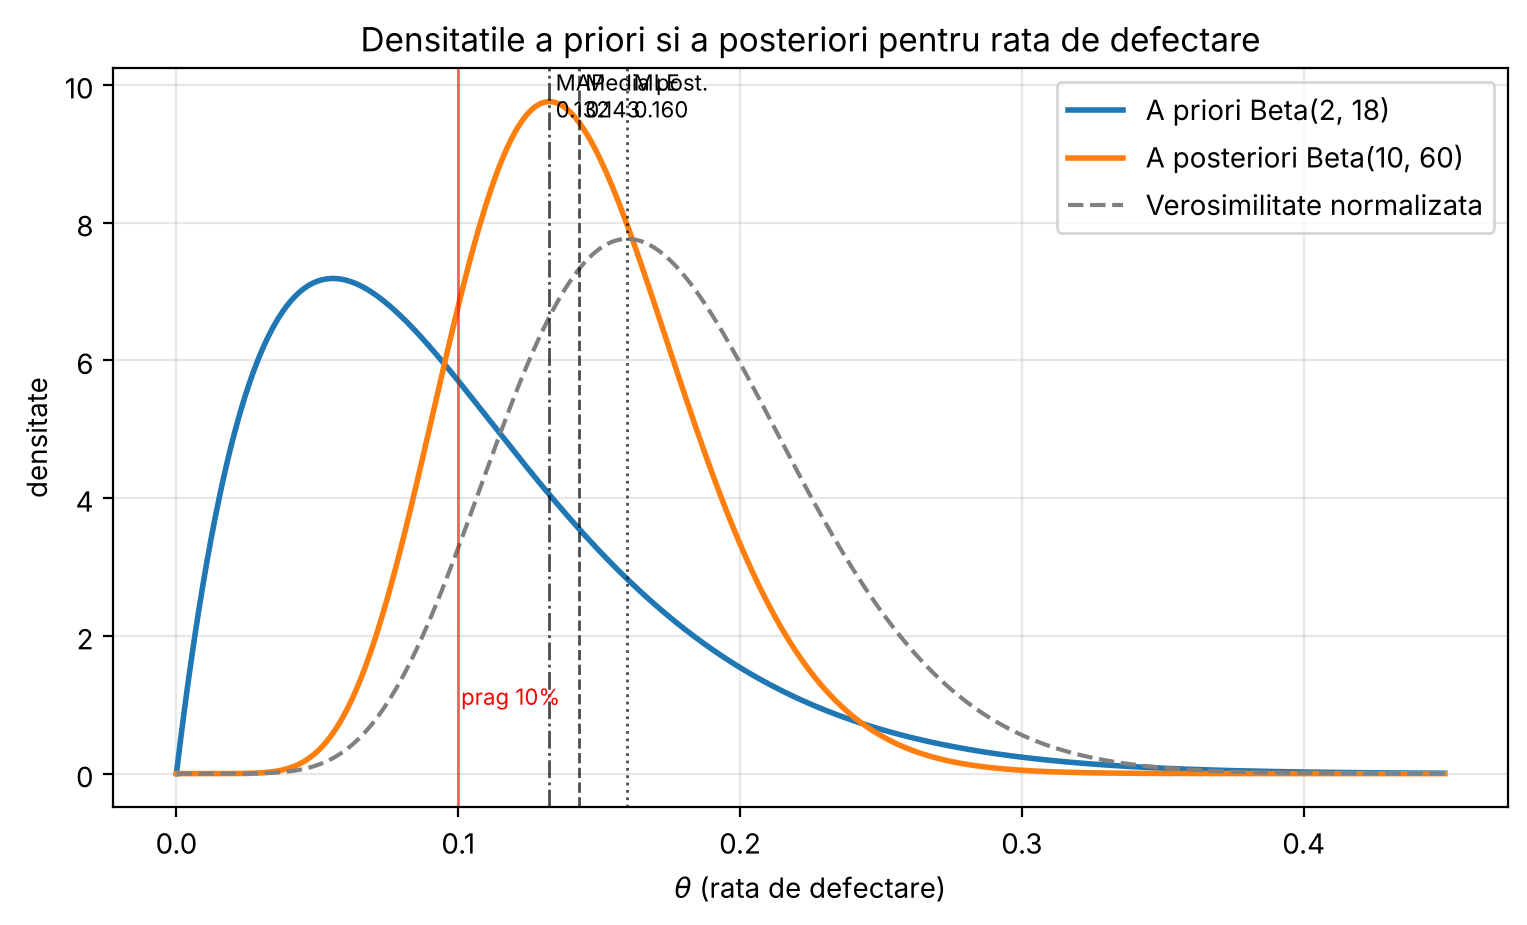

Abaterea standard a priori    : 0.0655
Abaterea standard a posteriori: 0.0415


In [6]:
th = np.linspace(0, 0.45, 1000)
fig, ax = plt.subplots()
ax.plot(th, prior.pdf(th), lw=2, label="A priori Beta(2, 18)")
ax.plot(th, post.pdf(th), lw=2, label="A posteriori Beta(10, 60)")
# verosimilitatea normalizata (= densitatea Beta(9, 43)), doar pentru comparatie
ax.plot(th, stats.beta(y + 1, n - y + 1).pdf(th), lw=1.5, ls="--", color="gray",
        label="Verosimilitate normalizata")
for val, nume, st in [(mle, "MLE", ":"), (map_, "MAP", "-."), (media_post, "Media post.", "--")]:
    ax.axvline(val, color="k", ls=st, lw=1, alpha=0.7)
    ax.text(val, ax.get_ylim()[1] * 0.93, f" {nume}\n {val:.3f}", fontsize=8)
ax.axvline(0.10, color="red", lw=1, alpha=0.6)
ax.text(0.101, 1, "prag 10%", color="red", fontsize=8)
ax.set_xlabel(r"$\theta$ (rata de defectare)")
ax.set_ylabel("densitate")
ax.set_title("Densitatile a priori si a posteriori pentru rata de defectare")
ax.legend()
plt.show()

print(f"Abaterea standard a priori    : {prior.std():.4f}")
print(f"Abaterea standard a posteriori: {post.std():.4f}")

**Interpretare.** Distribuția a priori era centrată în jurul valorii 0.10 și relativ largă (abatere standard ≈ 0.065). Datele (16 % defecte în eșantion) au avut două efecte:

1. **au deplasat** masa de probabilitate spre dreapta, adică spre rate de defectare mai mari (media a crescut de la 0.10 la 0.143);
2. **au redus incertitudinea**: curba a posteriori este mult mai îngustă (abatere standard ≈ 0.042), pentru că acum avem echivalentul a 70 de observații în loc de 20.

Distribuția a posteriori se află între distribuția a priori și verosimilitate, mai aproape de verosimilitate, deoarece datele au o pondere mai mare.

## e) Incertitudine: interval credibil central de 95 %

Căutăm $[q_{0.025},\, q_{0.975}]$ astfel încât $P(\theta < q_{0.025}\mid y) = 0.025$ și $P(\theta > q_{0.975}\mid y) = 0.025$, adică cuantilele distribuției Beta(10, 60):

$$
q_p = F^{-1}_{\mathrm{Beta}(10,60)}(p).
$$

In [7]:
ic_low, ic_high = post.ppf([0.025, 0.975])
print(f"Interval credibil central 95%: [{ic_low:.4f}, {ic_high:.4f}]")
print(f"Verificare: P(theta in interval) = {post.cdf(ic_high) - post.cdf(ic_low):.4f}")

# comparatie: intervalul de incredere Wald (frecventist)
se = np.sqrt(mle * (1 - mle) / n)
print(f"(Comparatie) IC Wald 95% frecventist: [{mle - 1.96*se:.4f}, {mle + 1.96*se:.4f}]")

Interval credibil central 95%: [0.0717, 0.2332]
Verificare: P(theta in interval) = 0.9500
(Comparatie) IC Wald 95% frecventist: [0.0584, 0.2616]


**Interpretare.** Având în vedere distribuția a priori și datele observate, cu probabilitate 95 % rata reală de defectare se află aproximativ între **7.2 % și 23.3 %**. Spre deosebire de un interval de încredere frecventist, aceasta este o afirmație probabilistică directă despre $\theta$.

Intervalul este destul de larg, ceea ce arată că 50 de componente nu sunt suficiente pentru a determina precis rata de defectare. De asemenea, intervalul conține pragul de 10 %, dar majoritatea lui este deasupra pragului.

## f) Decizie practică: $P(\theta < 0.10 \mid Y = 8)$

$$
P(\theta < 0.10 \mid Y=8) = \int_0^{0.10} \frac{\theta^{9}(1-\theta)^{59}}{B(10,60)}\,d\theta = F_{\mathrm{Beta}(10,60)}(0.10).
$$

In [8]:
p_sub_10 = post.cdf(0.10)
print(f"P(theta < 0.10 | Y = 8) = {p_sub_10:.4f}")
print(f"P(theta >= 0.10 | Y = 8) = {1 - p_sub_10:.4f}")
print(f"(Comparatie, a priori) P(theta < 0.10) = {prior.cdf(0.10):.4f}")

# verificare Monte Carlo
rng1 = np.random.default_rng(2026)
esantion = rng1.beta(a_post, b_post, size=1_000_000)
print(f"Verificare Monte Carlo (10^6 extrageri): {np.mean(esantion < 0.10):.4f}")

P(theta < 0.10 | Y = 8) = 0.1484
P(theta >= 0.10 | Y = 8) = 0.8516
(Comparatie, a priori) P(theta < 0.10) = 0.5797
Verificare Monte Carlo (10^6 extrageri): 0.1479


**Discuție.** Probabilitatea a posteriori ca rata de defectare să fie sub 10 % este de aproximativ **15 %**. Așadar, datele **nu susțin** cerința: cu probabilitate de circa 85 % rata reală depășește 10 %.

Înainte de testare, credința era aproape 60/40 în favoarea respectării cerinței. După cele 8 defecte din 50, raportul s-a inversat puternic.

Recomandare: fabrica nu poate afirma că procesul respectă pragul de 10 %. Ar trebui fie să îmbunătățească procesul, fie să testeze mai multe componente, dacă vrea să confirme sau să infirme cu mai multă certitudine. Însă, cu rata observată de 16 %, este puțin probabil ca date suplimentare să schimbe concluzia.

## g) Predicție Bayesiană

Fie $X$ numărul de defecte în 10 componente noi; $X\mid\theta \sim \mathrm{Bin}(10,\theta)$, independent de $Y$ condiționat de $\theta$. Atunci

$$
P(X=0\mid Y=8) = \int_0^1 (1-\theta)^{10}\,p(\theta\mid Y=8)\,d\theta
= \int_0^1 (1-\theta)^{10}\,\frac{\theta^{9}(1-\theta)^{59}}{B(10,60)}\,d\theta
= \frac{B(10,\,70)}{B(10,\,60)} .
$$

Folosind $B(a,b)=\dfrac{\Gamma(a)\Gamma(b)}{\Gamma(a+b)}$ și $\Gamma(z+1)=z\Gamma(z)$:

$$
\frac{B(10,70)}{B(10,60)} = \frac{\Gamma(70)\,\Gamma(70)}{\Gamma(60)\,\Gamma(80)} = \prod_{k=0}^{9}\frac{60+k}{70+k} .
$$

(Aceasta este probabilitatea în $0$ a distribuției **Beta-Binomiale** $\mathrm{BetaBin}(10;\,10,\,60)$.)

In [9]:
m = 10
p_formula = np.exp(betaln(a_post, b_post + m) - betaln(a_post, b_post))
p_produs = np.prod([(b_post + k) / (a_post + b_post + k) for k in range(m)])
p_betabinom = stats.betabinom(m, a_post, b_post).pmf(0)

from scipy.integrate import quad
p_integral, _ = quad(lambda t: (1 - t)**m * post.pdf(t), 0, 1)

p_mc = np.mean((1 - esantion)**m)          # Monte Carlo cu extragerile de la f)

print(f"Formula cu functia Beta : {p_formula:.5f}")
print(f"Produsul explicit       : {p_produs:.5f}")
print(f"Integrare numerica      : {p_integral:.5f}")
print(f"scipy betabinom.pmf(0)  : {p_betabinom:.5f}")
print(f"Monte Carlo             : {p_mc:.5f}")
print()
print(f"(Comparatie 'plug-in' cu MLE: (1-0.16)^10 = {(1-mle)**m:.5f};"
      f" cu media posteriori: (1-1/7)^10 = {(1-media_post)**m:.5f})")

Formula cu functia Beta : 0.23602
Produsul explicit       : 0.23602
Integrare numerica      : 0.23602
scipy betabinom.pmf(0)  : 0.23602
Monte Carlo             : 0.23591

(Comparatie 'plug-in' cu MLE: (1-0.16)^10 = 0.17490; cu media posteriori: (1-1/7)^10 = 0.21406)


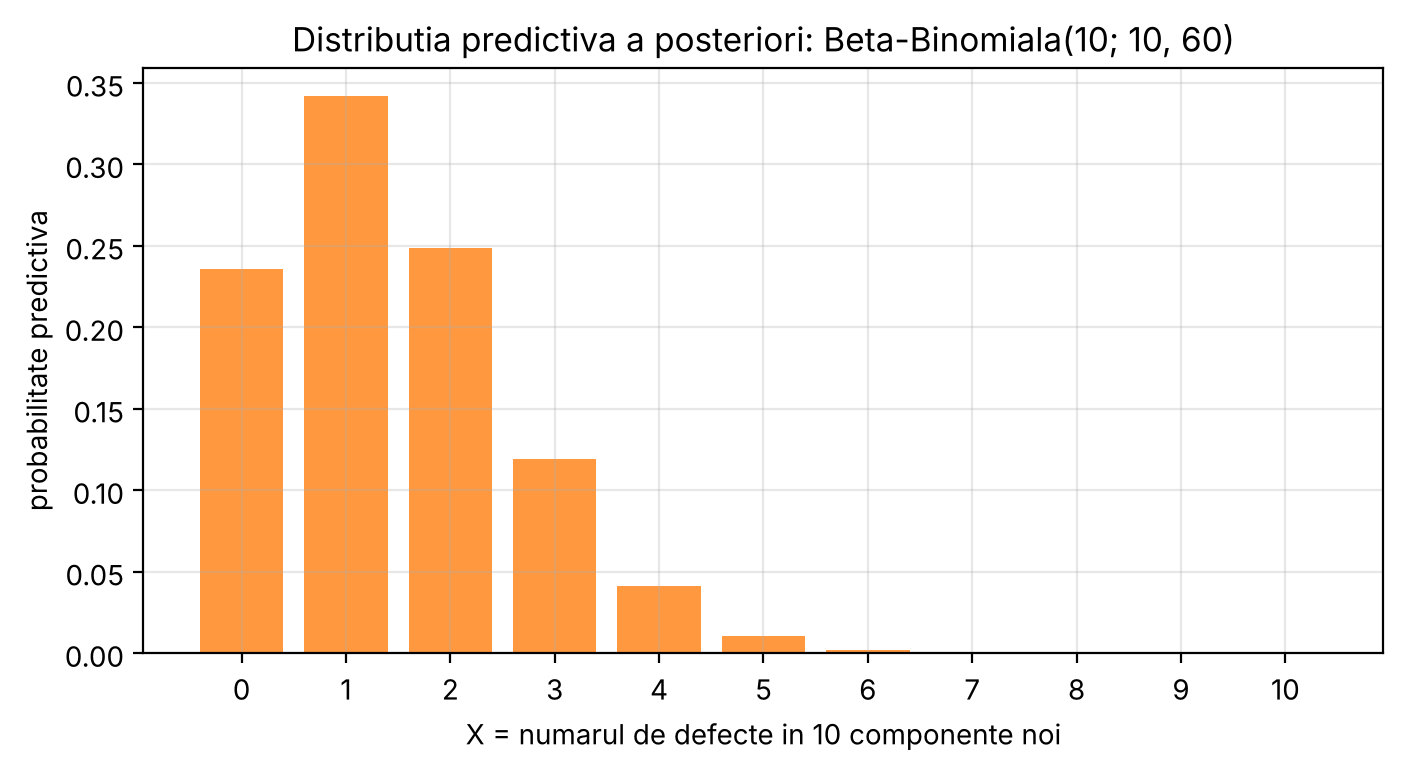

In [10]:
k = np.arange(0, m + 1)
pred = stats.betabinom(m, a_post, b_post).pmf(k)
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar(k, pred, color="tab:orange", alpha=0.8)
ax.set_xticks(k)
ax.set_xlabel("X = numarul de defecte in 10 componente noi")
ax.set_ylabel("probabilitate predictiva")
ax.set_title("Distributia predictiva a posteriori: Beta-Binomiala(10; 10, 60)")
plt.show()

**Interpretare.** Probabilitatea predictivă ca niciuna dintre cele 10 componente noi să nu fie defectă este de aproximativ **23.6 %**.

Este puțin mai mare decât estimarea „plug-in” $(1-\bar\theta)^{10}\approx 21.4\%$ (și mult mai mare decât $(1-0.16)^{10}\approx 17.5\%$ cu MLE), deoarece predicția Bayesiană face media peste toată incertitudinea despre $\theta$. Funcția $(1-\theta)^{10}$ este convexă, deci, din inegalitatea lui Jensen, $E[(1-\theta)^{10}] \ge (1-E[\theta])^{10}$. Valorile mici ale lui $\theta$ (încă plauzibile) contribuie mult la probabilitate.

---
# Exercițiul 2. Deschiderea unui restaurant fast-food (simulare Monte Carlo)

**Model.**
* Sosiri: proces Poisson cu $\lambda = 20$ clienți/oră, deci timpii dintre sosiri sunt $\mathrm{Exp}$ cu media $60/20 = 3$ minute.
* Casa (stația 1): timp de plată $S_i \sim \mathrm{Exp}(\text{medie } 2 \text{ min})$.
* Bucătăria (stația 2): timp de preparare $C_i \sim \mathrm{Exp}(\text{medie } \alpha \text{ min})$.
* Câte un singur server la fiecare stație, disciplină FIFO, sistem gol la $t=0$. Urmărim clienții sosiți în $[0, 60]$ minute până la servirea completă.

Este un sistem de **două cozi în serie (tandem)**.

## a) Simularea unei ore

**Cum tratăm cele două cozi.** Notăm cu $A_i$ momentul sosirii clientului $i$ (în ordine crescătoare), cu $D^{(1)}_i$ momentul în care termină plata și cu $D^{(2)}_i$ momentul în care primește mâncarea. Cu $D^{(1)}_0 = D^{(2)}_0 = 0$ (sistem gol):

**Coada la casă.** Clientul $i$ începe plata când a sosit și casa s-a eliberat de clientul $i-1$:
$$
\text{start}^{(1)}_i = \max\big(A_i,\ D^{(1)}_{i-1}\big), \qquad D^{(1)}_i = \text{start}^{(1)}_i + S_i .
$$

**Coada la bucătărie.** Comanda intră în coada bucătăriei la $D^{(1)}_i$. Deoarece casa este FIFO, comenzile ajung la bucătărie tot în ordinea sosirii, deci FIFO se păstrează:
$$
\text{start}^{(2)}_i = \max\big(D^{(1)}_i,\ D^{(2)}_{i-1}\big), \qquad D^{(2)}_i = \text{start}^{(2)}_i + C_i .
$$

**Timpul total în sistem:** $T_i = D^{(2)}_i - A_i$.

**Timpul de așteptare efectivă (fără servire):**
$$
W_i = \underbrace{\big(\text{start}^{(1)}_i - A_i\big)}_{\text{coada la casa}} + \underbrace{\big(\text{start}^{(2)}_i - D^{(1)}_i\big)}_{\text{coada la bucatarie}} = T_i - S_i - C_i .
$$

Sosirile sunt generate ca sume cumulate de exponențiale cu media 3; păstrăm doar sosirile cu $A_i \le 60$. Mai jos este întâi o versiune simplă (o singură oră, cu un tabel de verificare), apoi o versiune vectorizată pentru multe simulări.

In [11]:
LAMBDA = 20 / 60      # clienti pe minut
MEDIE_PLATA = 2.0     # minute
DURATA = 60.0         # minute
PRAG = 15.0           # minute

def simuleaza_o_ora(alpha, rng):
    # 1) momentele sosirilor in [0, 60]
    sosiri = []
    t = rng.exponential(1 / LAMBDA)
    while t <= DURATA:
        sosiri.append(t)
        t += rng.exponential(1 / LAMBDA)
    A = np.array(sosiri)
    k = len(A)
    # 2) timpii de servire
    S = rng.exponential(MEDIE_PLATA, k)
    C = rng.exponential(alpha, k)
    # 3) cele doua cozi FIFO in serie
    start1 = np.zeros(k); D1 = np.zeros(k)
    start2 = np.zeros(k); D2 = np.zeros(k)
    liber1 = liber2 = 0.0           # momentul in care se elibereaza fiecare statie
    for i in range(k):
        start1[i] = max(A[i], liber1); D1[i] = start1[i] + S[i]; liber1 = D1[i]
        start2[i] = max(D1[i], liber2); D2[i] = start2[i] + C[i]; liber2 = D2[i]
    T = D2 - A
    W = (start1 - A) + (start2 - D1)
    return dict(A=A, S=S, start1=start1, D1=D1, C=C, start2=start2, D2=D2, T=T, W=W)

rng_demo = np.random.default_rng(7)
r = simuleaza_o_ora(alpha=1.0, rng=rng_demo)
print(f"Clienti sositi in ora simulata: {len(r['A'])}")
print(f"{'i':>3} {'sosire':>7} {'plata':>6} {'start1':>7} {'D1':>7} {'gatit':>6} {'start2':>7} {'D2':>7} {'T':>6} {'W':>6}")
for i in range(min(12, len(r['A']))):
    print(f"{i+1:>3} {r['A'][i]:7.2f} {r['S'][i]:6.2f} {r['start1'][i]:7.2f} {r['D1'][i]:7.2f} "
          f"{r['C'][i]:6.2f} {r['start2'][i]:7.2f} {r['D2'][i]:7.2f} {r['T'][i]:6.2f} {r['W'][i]:6.2f}")
print(f"\nTimpul maxim in sistem in aceasta ora: {r['T'].max():.2f} min ->",
      "toti <= 15 min" if r['T'].max() <= PRAG else "cel putin un client > 15 min")

Clienti sositi in ora simulata: 19
  i  sosire  plata  start1      D1  gatit  start2      D2      T      W
  1    2.12   0.15    2.12    2.27   1.40    2.27    3.68   1.55   0.00
  2    5.20   0.12    5.20    5.32   3.80    5.32    9.11   3.92   0.00
  3    6.90   2.45    6.90    9.35   1.75    9.35   11.10   4.20   0.00
  4    9.59   1.55    9.59   11.13   2.24   11.13   13.38   3.79   0.00
  5   10.21   4.39   11.13   15.53   0.14   15.53   15.67   5.46   0.93
  6   20.36   0.95   20.36   21.31   0.30   21.31   21.61   1.25   0.00
  7   20.39   1.04   21.31   22.35   0.24   22.35   22.59   2.20   0.92
  8   28.82   2.36   28.82   31.18   1.15   31.18   32.33   3.51   0.00
  9   30.54   1.05   31.18   32.23   1.22   32.33   33.55   3.01   0.73
 10   31.44   0.04   32.23   32.28   0.13   33.55   33.68   2.23   2.06
 11   33.07   0.59   33.07   33.65   0.38   33.68   34.06   0.99   0.02
 12   34.00   2.03   34.00   36.03   1.07   36.03   37.10   3.10   0.00

Timpul maxim in sistem in ac

**Versiunea vectorizată (pentru multe simulări).** Generăm $N$ ore simultan. Fiecare oră are un număr aleator de clienți, $K\sim\mathrm{Poisson}(20)$, așa că alocăm $M = 80$ de poziții pe rând și „mascăm” clienții cu $A_i > 60$. Avem $P(K > 80) \approx 10^{-20}$, deci trunchierea este neglijabilă (o verificăm explicit în cod).

**Numere aleatoare comune (CRN).** Generăm o singură dată $E_i \sim \mathrm{Exp}(1)$ și punem $C_i = \alpha E_i$. Astfel, pentru orice $\alpha$ se folosesc aceleași sosiri și aceiași timpi de bază. Consecințe:
* comparațiile între valori diferite ale lui $\alpha$ au zgomot mult mai mic;
* în fiecare replicare, $D^{(2)}_i$ este crescător în $\alpha$, deci probabilitatea estimată $\hat p(\alpha)$ este **exact monotonă descrescătoare**. Asta permite căutarea lui $\alpha$ prin bisecție.

In [12]:
SEED = 2026
N_SIM = 20_000
M_MAX = 80

class Simulator:
    # N ore simulate cu numere aleatoare comune (CRN) pentru toate valorile lui alpha
    def __init__(self, n_sim=N_SIM, seed=SEED, m_max=M_MAX):
        rng = np.random.default_rng(seed)
        self.A = np.cumsum(rng.exponential(1 / LAMBDA, (n_sim, m_max)), axis=1)
        self.S = rng.exponential(MEDIE_PLATA, (n_sim, m_max))
        self.E = rng.exponential(1.0, (n_sim, m_max))      # C = alpha * E
        self.masca = self.A <= DURATA                       # clientii sositi in [0, 60]
        assert not self.masca[:, -1].any(), "M_MAX prea mic"
        self.n_sim = n_sim

    def ruleaza(self, alpha):
        A, S, C = self.A, self.S, alpha * self.E
        n, m = A.shape
        T = np.empty((n, m)); W = np.empty((n, m))
        liber1 = np.zeros(n); liber2 = np.zeros(n)
        for i in range(m):                                  # recursia pe clienti, vectorizata pe ore
            s1 = np.maximum(A[:, i], liber1); d1 = s1 + S[:, i]
            s2 = np.maximum(d1, liber2);      d2 = s2 + C[:, i]
            T[:, i] = d2 - A[:, i]
            W[:, i] = (s1 - A[:, i]) + (s2 - d1)
            liber1, liber2 = d1, d2
        return T, W

    def p_toti(self, alpha, prag=PRAG):
        # P(toti clientii din ora au T <= prag); o ora fara clienti conteaza ca succes
        T, _ = self.ruleaza(alpha)
        T_max = np.where(self.masca, T, -np.inf).max(axis=1)
        return np.mean(T_max <= prag)

    def p_client(self, alpha, prag=PRAG):
        # fractia tuturor clientilor (din toate orele) cu T <= prag
        T, _ = self.ruleaza(alpha)
        return np.mean(T[self.masca] <= prag)

sim = Simulator()
nr = sim.masca.sum(axis=1)
print(f"{N_SIM} ore simulate, seed = {SEED}")
print(f"Numar mediu de clienti pe ora: {nr.mean():.2f} (teoretic 20), maxim observat: {nr.max()}")

# validare: aceeasi medie si cu simularea simpla (bucla Python), pe alte numere aleatoare
rng_v = np.random.default_rng(99)
T_simplu = np.concatenate([simuleaza_o_ora(1.0, rng_v)['T'] for _ in range(3000)])
print(f"Timp mediu in sistem, alpha=1: vectorizat {sim.ruleaza(1.0)[0][sim.masca].mean():.3f} min,"
      f" simplu {T_simplu.mean():.3f} min")

20000 ore simulate, seed = 2026
Numar mediu de clienti pe ora: 19.96 (teoretic 20), maxim observat: 39


Timp mediu in sistem, alpha=1: vectorizat 6.384 min, simplu 6.463 min


## b) Probabilitatea ca **toți** clienții orei să fie serviți în ≤ 15 minute

Pentru o oră simulată $j$, evenimentul de interes este
$$
\mathcal{E}_j = \Big\{\max_{i:\,A_i\le 60} T_i \le 15\Big\},
$$
iar estimatorul Monte Carlo este $\hat p(\alpha) = \frac1N \sum_{j=1}^N \mathbf 1_{\mathcal E_j}$, cu eroarea standard $\sqrt{\hat p(1-\hat p)/N}$.

Atenție: condiția se referă la **toți** clienții dintr-o oră, nu la un client ales aleatoriu. Estimăm $\hat p(\alpha)$ pe o grilă de valori:

In [13]:
grila_alpha = np.round(np.arange(0.0, 4.01, 0.25), 2)
p_toti = np.array([sim.p_toti(a) for a in grila_alpha])
p_client = np.array([sim.p_client(a) for a in grila_alpha])
se_toti = np.sqrt(p_toti * (1 - p_toti) / N_SIM)

print(f"{'alpha':>6} | {'P(toti <= 15)':>14} {'+-1.96*SE':>10} | {'P(un client <= 15)':>18}")
for a, p, s, pc in zip(grila_alpha, p_toti, se_toti, p_client):
    print(f"{a:6.2f} | {p:14.4f} {1.96*s:10.4f} | {pc:18.4f}")

 alpha |  P(toti <= 15)  +-1.96*SE | P(un client <= 15)
  0.00 |         0.8112     0.0054 |             0.9525
  0.25 |         0.8012     0.0055 |             0.9497
  0.50 |         0.7855     0.0057 |             0.9460
  0.75 |         0.7667     0.0059 |             0.9409
  1.00 |         0.7367     0.0061 |             0.9331
  1.25 |         0.6916     0.0064 |             0.9204
  1.50 |         0.6286     0.0067 |             0.8998
  1.75 |         0.5409     0.0069 |             0.8670
  2.00 |         0.4489     0.0069 |             0.8214
  2.25 |         0.3553     0.0066 |             0.7648
  2.50 |         0.2779     0.0062 |             0.7026
  2.75 |         0.2129     0.0057 |             0.6390
  3.00 |         0.1593     0.0051 |             0.5758
  3.25 |         0.1188     0.0045 |             0.5175
  3.50 |         0.0886     0.0039 |             0.4653
  3.75 |         0.0664     0.0035 |             0.4196
  4.00 |         0.0491     0.0030 |            

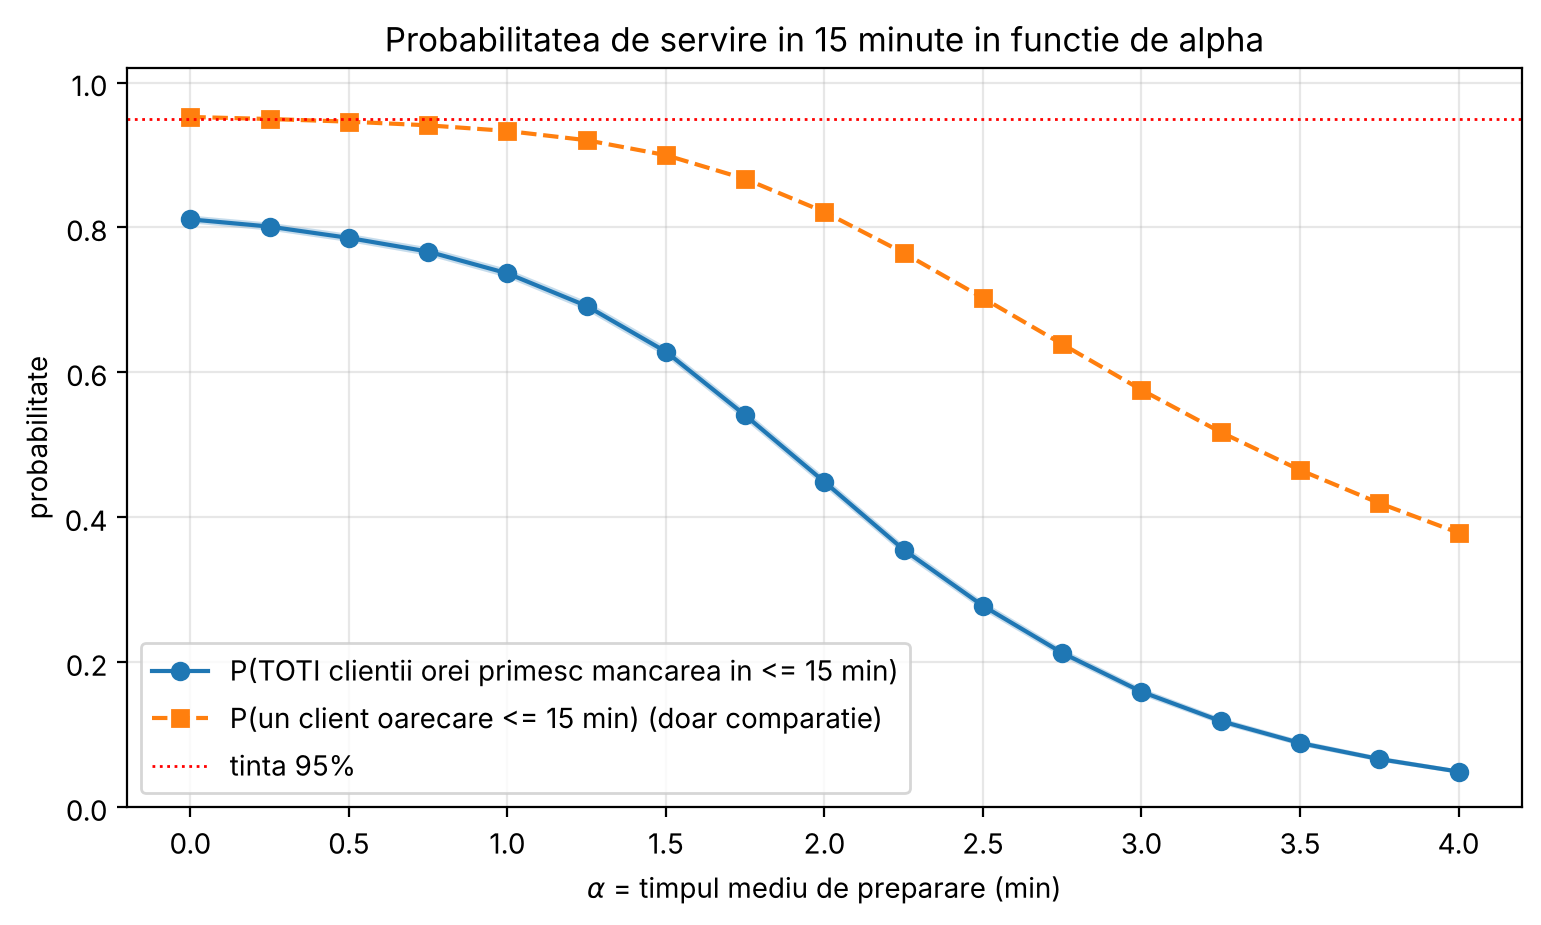

Chiar si pentru alpha = 0 (gatit instantaneu): P(toti <= 15) = 0.8112


In [14]:
fig, ax = plt.subplots()
ax.plot(grila_alpha, p_toti, "o-", label="P(TOTI clientii orei primesc mancarea in <= 15 min)")
ax.fill_between(grila_alpha, p_toti - 1.96 * se_toti, p_toti + 1.96 * se_toti, alpha=0.25)
ax.plot(grila_alpha, p_client, "s--", label="P(un client oarecare <= 15 min) (doar comparatie)")
ax.axhline(0.95, color="red", lw=1, ls=":", label="tinta 95%")
ax.set_xlabel(r"$\alpha$ = timpul mediu de preparare (min)")
ax.set_ylabel("probabilitate")
ax.set_ylim(0, 1.02)
ax.set_title("Probabilitatea de servire in 15 minute in functie de alpha")
ax.legend(loc="lower left")
plt.show()

print(f"Chiar si pentru alpha = 0 (gatit instantaneu): P(toti <= 15) = {sim.p_toti(0.0):.4f}")

### Căutarea celui mai mare $\alpha$ cu $\hat p(\alpha) \ge 0.95$

Deoarece $\hat p(\alpha)$ este monoton descrescător (datorită CRN), folosim **bisecția**: dacă $\hat p(0) < 0.95$, nu există nicio soluție; altfel restrângem intervalul $[\alpha_{\text{jos}}, \alpha_{\text{sus}}]$ până la o toleranță de $10^{-3}$ minute.

In [15]:
def cel_mai_mare_alpha(f, tinta=0.95, a_sus=20.0, tol=1e-3):
    # cel mai mare alpha cu f(alpha) >= tinta, presupunand f descrescatoare; None daca nu exista
    if f(0.0) < tinta:
        return None
    a_jos = 0.0
    while f(a_sus) >= tinta:
        a_sus *= 2
    while a_sus - a_jos > tol:
        mij = (a_jos + a_sus) / 2
        if f(mij) >= tinta:
            a_jos = mij
        else:
            a_sus = mij
    return a_jos

alpha_star = cel_mai_mare_alpha(sim.p_toti)
print("Cel mai mare alpha cu P(toti <= 15 min) >= 0.95:", alpha_star)

Cel mai mare alpha cu P(toti <= 15 min) >= 0.95: None


### Rezultat: cerința de 95 % este imposibil de atins în acest model

Simularea arată că $\hat p(\alpha)$ este sub 0.95 **pentru orice $\alpha \ge 0$**. Chiar și la limita $\alpha \to 0$ (gătit instantaneu), probabilitatea este doar ≈ **0.81**. Cu alte cuvinte, **nu există nicio valoare a lui $\alpha$** pentru care toți clienții unei ore să fie serviți în 15 minute cu probabilitate de 95 %.

**De ce?** Gâtuirea apare deja la casă:
* casa singură este o coadă M/M/1 cu utilizare $\rho = \lambda \cdot 2 = \tfrac{20}{60}\cdot 2 = \tfrac23$;
* în regim staționar, timpul în sistem la o coadă M/M/1 este $\mathrm{Exp}(\mu-\lambda)$, cu $\mu - \lambda = \tfrac12 - \tfrac13 = \tfrac16$ pe minut, deci
$$P(T^{(1)} > 15) = e^{-15/6} = e^{-2.5} \approx 0.082 ;$$
* pornind cu sistemul gol, ora nu ajunge complet în regim staționar, așa că pentru un client oarecare probabilitatea scade la circa 5 %. Însă într-o oră sosesc în medie 20 de clienți, iar dacă se formează o coadă lungă, mai mulți clienți consecutivi depășesc pragul. Probabilitatea ca **măcar unul** să depășească 15 minute rămâne de aproximativ 19 %.

Mai jos verificăm acest lucru direct și calculăm ce prag de timp ar fi realist pentru 95 %:

In [16]:
T0, _ = sim.ruleaza(0.0)
Tmax0 = np.where(sim.masca, T0, -np.inf).max(axis=1)
print(f"alpha = 0: P(toti <= 15) = {np.mean(Tmax0 <= 15):.4f}  (doar coada la casa)")
print(f"alpha = 0: cuantila 95% a timpului MAXIM din ora = {np.quantile(Tmax0, 0.95):.1f} min")
print(f"Teoretic M/M/1 stationar: P(T_casa > 15) = exp(-2.5) = {np.exp(-2.5):.4f};"
      f" simulat (un client oarecare, alpha=0): {np.mean(T0[sim.masca] > 15):.4f}")

print("\nCel mai mare alpha cu P(toti <= L) >= 0.95, pentru diferite praguri L:")
for L in [15, 20, 22, 25, 30]:
    a = cel_mai_mare_alpha(lambda al: sim.p_toti(al, prag=L))
    print(f"  L = {L:2d} min -> alpha* = {'nu exista' if a is None else f'{a:.2f} min'}")

alpha = 0: P(toti <= 15) = 0.8112  (doar coada la casa)
alpha = 0: cuantila 95% a timpului MAXIM din ora = 21.8 min
Teoretic M/M/1 stationar: P(T_casa > 15) = exp(-2.5) = 0.0821; simulat (un client oarecare, alpha=0): 0.0475

Cel mai mare alpha cu P(toti <= L) >= 0.95, pentru diferite praguri L:


  L = 15 min -> alpha* = nu exista


  L = 20 min -> alpha* = nu exista


  L = 22 min -> alpha* = 0.16 min


  L = 25 min -> alpha* = 1.40 min


  L = 30 min -> alpha* = 1.96 min


**Concluzie pentru (b).** În modelul dat (o singură casă cu plata în medie de 2 minute), răspunsul corect este: **nu există $\alpha$ care să satisfacă cerința**. Probabilitatea maximă, atinsă pentru $\alpha\to 0$, este ≈ 0.81. Ca să ajungă la 95 %, restaurantul trebuie să reducă timpul la casă (de exemplu, o a doua casă sau plată mai rapidă) sau să accepte un prag de timp mai mare. Tabelul de mai sus arată că, păstrând garanția pentru *toți* clienții, pragul ar trebui să fie de cel puțin ~22 de minute.

**Valoare de referință pentru punctul (c).** Ca să putem răspunde totuși la (c), folosim criteriul mai slab „un client **oarecare** este servit în ≤ 15 min cu probabilitate ≥ 95 %” (curba punctată din grafic). Subliniem că aceasta **nu** este condiția cerută, ci doar o referință. Cerința strictă nu poate fi îndeplinită.

In [17]:
alpha_ref = cel_mai_mare_alpha(sim.p_client)
print(f"alpha de referinta (criteriul 'un client oarecare'): {alpha_ref:.3f} min")
print(f"  P(un client oarecare <= 15 min) = {sim.p_client(alpha_ref):.4f}")
print(f"  P(TOTI clientii orei <= 15 min) = {sim.p_toti(alpha_ref):.4f}  (sub 95%, ca la orice alpha)")

alpha de referinta (criteriul 'un client oarecare'): 0.219 min
  P(un client oarecare <= 15 min) = 0.9500


  P(TOTI clientii orei <= 15 min) = 0.8027  (sub 95%, ca la orice alpha)


## c) Timpul mediu în sistem și timpul mediu de așteptare

Pentru $\alpha_{\text{ref}}$ calculăm, pe toți clienții tuturor orelor simulate:
* $\bar T$ = timpul mediu de la sosire până la primirea mâncării;
* $\bar W$ = timpul mediu de așteptare efectivă la cele două cozi, adică $T - S - C$.

Ca referință, raportăm aceleași mărimi și pentru alte valori ale lui $\alpha$.

In [18]:
def statistici(alpha):
    T, W = sim.ruleaza(alpha)
    t, w = T[sim.masca], W[sim.masca]
    return t.mean(), t.std(ddof=1) / np.sqrt(t.size), w.mean(), np.quantile(t, 0.95)

Tm, Tse, Wm, Tq = statistici(alpha_ref)
print(f"alpha = {alpha_ref:.3f} min (referinta):")
print(f"  timp mediu sosire -> mancare : {Tm:.2f} min  (+- {1.96*Tse:.2f})")
print(f"  timp mediu de asteptare (fara servire): {Wm:.2f} min")
print(f"  timp mediu de servire efectiva: {Tm - Wm:.2f} min (~ 2 + alpha = {2 + alpha_ref:.2f})")

print(f"\n{'alpha':>6} {'T mediu':>8} {'W mediu':>8} {'cuantila 95% T':>15} {'P(toti<=15)':>12}")
for a in [0.0, alpha_ref, 0.5, 1.0, 1.5, 2.0]:
    Tm_, _, Wm_, Tq_ = statistici(a)
    print(f"{a:6.2f} {Tm_:8.2f} {Wm_:8.2f} {Tq_:15.2f} {sim.p_toti(a):12.4f}")

alpha = 0.219 min (referinta):
  timp mediu sosire -> mancare : 5.19 min  (+- 0.02)
  timp mediu de asteptare (fara servire): 2.97 min
  timp mediu de servire efectiva: 2.22 min (~ 2 + alpha = 2.22)

 alpha  T mediu  W mediu  cuantila 95% T  P(toti<=15)


  0.00     4.96     2.96           14.76       0.8112


  0.22     5.19     2.97           15.00       0.8027


  0.50     5.55     3.05           15.39       0.7855


  1.00     6.38     3.38           16.43       0.7367


  1.50     7.63     4.12           18.49       0.6286


  2.00     9.51     5.51           22.56       0.4489


**Interpretare.** Pentru $\alpha_{\text{ref}}\approx 0.22$ min, un client petrece în medie circa 5.2 minute de la sosire până primește mâncarea. Aproximativ 2.2 minute sunt servire efectivă ($2 + \alpha$), iar restul de circa 3 minute este așteptare, aproape în întregime la coada de la casă. Media este mult sub 15 minute, dar condiția „toți clienții” este dominată de cel mai ghinionist client al orei, de aceea e mult mai severă.

## d) Detalii de reproductibilitate și variabilitate

* **Număr de simulări:** $N = 20\,000$ de ore independente pentru fiecare valoare a lui $\alpha$. Eroarea standard a lui $\hat p$ este $\sqrt{\hat p(1-\hat p)/N}\le 0.0035$, deci intervalul de 95 % are o semilățime de cel mult ±0.007.
* **Sămânța aleatoare:** `SEED = 2026` (`numpy.random.default_rng`), cu numere aleatoare comune pentru toate valorile lui $\alpha$ ($C_i = \alpha E_i$).
* **Metoda de căutare a lui $\alpha$:** întâi o grilă cu pasul 0.25 (pentru grafic), apoi **bisecție** pe $[0, 20]$ până la toleranța $10^{-3}$. Bisecția este justificată, deoarece cu CRN $\hat p(\alpha)$ este monoton descrescător. Pentru cerința strictă, bisecția se oprește din primul pas, pentru că $\hat p(0) < 0.95$.

**De ce se schimbă estimările de la o rulare la alta?** $\hat p(\alpha)$ și $\bar T$ sunt medii ale unor variabile aleatoare, deci sunt ele însele aleatoare. Cu altă sămânță obținem alte sosiri și alți timpi de servire, deci alte valori, care fluctuează în jurul valorilor reale cu o abatere de ordinul $1/\sqrt N$. Valoarea lui $\alpha^*$ găsită prin bisecție moștenește această variabilitate. În plus, curba $p(\alpha)$ este destul de plată lângă prag, așa că o mică eroare în $\hat p$ se traduce într-o eroare mai mare în $\alpha^*$.

Tabelul de mai jos confirmă acest efect: $\alpha_{\text{ref}}$ variază vizibil între semințe (aproximativ 0.1–0.4 min), deși $\bar T$ se schimbă puțin. Concluzia principală însă nu depinde de sămânță: $\hat p(0)\approx 0.81$ este la peste 40 de erori standard sub 0.95. Verificăm mai jos cu câteva semințe diferite:

In [19]:
print(f"{'seed':>6} {'P(toti<=15), alpha=0':>22} {'alpha_ref':>10} {'T mediu la alpha_ref':>21}")
for s in [1, 2, 3, 4, 5]:
    sim_s = Simulator(n_sim=10_000, seed=s)
    a_s = cel_mai_mare_alpha(sim_s.p_client)
    T_s, _ = sim_s.ruleaza(a_s)
    print(f"{s:6d} {sim_s.p_toti(0.0):22.4f} {a_s:10.3f} {T_s[sim_s.masca].mean():21.2f}")

  seed   P(toti<=15), alpha=0  alpha_ref  T mediu la alpha_ref


     1                 0.8081      0.367                  5.38


     2                 0.8137      0.398                  5.38


     3                 0.8126      0.128                  5.13


     4                 0.8054      0.214                  5.20


     5                 0.8051      0.085                  5.12


---
## Rezumat

**Exercițiul 1.** A posteriori: $\theta\mid y \sim \mathrm{Beta}(10, 60)$. MLE = 0.16, MAP ≈ 0.132, media a posteriori ≈ 0.143. Intervalul credibil 95 % este ≈ [0.072, 0.233]. $P(\theta<0.10\mid y)\approx 0.15$, deci datele nu susțin cerința de sub 10 %. Probabilitatea predictivă ca niciuna din 10 componente noi să nu fie defectă este ≈ 0.236.

**Exercițiul 2.** Cu o singură casă (plată medie de 2 min) și $\lambda = 20$/oră, probabilitatea ca **toți** clienții orei să fie serviți în ≤ 15 minute este cel mult ≈ 0.81 (la $\alpha \to 0$), deci **nu există $\alpha$** care să asigure 95 %. Pentru criteriul mai slab „un client oarecare”, $\alpha_{\text{ref}}\approx 0.22$ min (foarte sensibil la sămânță), timpul mediu în sistem este ≈ 5.2 min, iar așteptarea efectivă ≈ 3 min.